# 08 — Advanced Kinematic Validation

**Target:** MaNGA plate-IFU `8138-12704`  
**DAPTYPE:** `HYB10-MILESHC-MASTARSSP`

## Why this milestone is necessary
The previous analysis returned 2,194 unique stellar bins and reported that all 2,194 passed both standard and strict quality cuts. That may be correct, but it must be verified directly from the MAPS file before we interpret the derived quantities.

This notebook audits:
1. The documented channel descriptions and actual unique IDs in every `BINID` plane.
2. Whether stellar velocity and dispersion values are constant within the selected stellar bins.
3. The number of valid spatial pixels versus the number of unique stellar bins.
4. DAP mask flags and inverse-variance-derived formal errors.
5. The systemic-velocity and kinematic-PA calculations.
6. The λ_R implementation inputs and radial aperture coverage.
7. The sensitivity of conclusions to these checks.

**Do not assume that a plane index is correct simply because it produces a plausible number.** The notebook prints the FITS channel metadata first and asks you to confirm the stellar-kinematics bin plane before doing bin-level statistics.

## 1. Imports and reproducibility

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import pandas as pd

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 220,
    "font.size": 10,
})

np.set_printoptions(precision=4, suppress=True)

## 2. Locate and open the MAPS file

In [2]:
candidate_roots = [
    Path.cwd(),
    Path.cwd().parent,
    Path(r"D:\\KS\\manga-stellar-kinematics"),
]
PROJECT_ROOT = next(
    (p.resolve() for p in candidate_roots if (p / "data" / "raw").is_dir()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Set PROJECT_ROOT manually to your project folder.")

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUT_DIR / "figures"
REPORTS_DIR = OUTPUT_DIR / "reports"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

maps_matches = list(RAW_DIR.glob(
    "manga-8138-12704-MAPS-HYB10-MILESHC-MASTARSSP.fits*"
))
if len(maps_matches) != 1:
    raise FileNotFoundError(f"Expected exactly one MAPS file: {maps_matches}")
MAPS_PATH = maps_matches[0]
maps = fits.open(MAPS_PATH, memmap=True)

print("MAPS:", MAPS_PATH)
print("DAPTYPE header:", maps[0].header.get("DAPTYPE"))
print("DRP version:", maps[0].header.get("VERSDRP3"))
print("DAP version:", maps[0].header.get("VERSDAP"))

MAPS: D:\KS\manga-stellar-kinematics\data\raw\manga-8138-12704-MAPS-HYB10-MILESHC-MASTARSSP.fits.gz
DAPTYPE header: HYB10-MILESHC-MASTARSSP
DRP version: v3_1_1
DAP version: 3.1.0


## 3. Inspect BINID channel metadata before selecting a plane

In [3]:
if "BINID" not in {h.name.upper() for h in maps}:
    raise KeyError("MAPS file does not contain BINID.")

binid_hdu = maps["BINID"]
binid_all = np.asarray(binid_hdu.data)
print("BINID shape:", binid_all.shape)
print("\nBINID header cards relevant to channel definitions:")
for key in binid_hdu.header:
    if key.startswith(("C", "B", "HDU", "EXT")):
        value = binid_hdu.header[key]
        comment = binid_hdu.header.comments[key]
        if key.startswith(("C", "B")):
            print(f"{key:10s} = {value!s:30s} / {comment}")

print("\nFull BINID header:")
print(binid_hdu.header)

BINID shape: (5, 72, 72)

BINID header cards relevant to channel definitions:
BITPIX     = 32                             / array data type
CRPIX1     = 37.0                           / Pixel coordinate of reference point
CRPIX2     = 37.0                           / Pixel coordinate of reference point
CRPIX3     = 1.0                            / Pixel coordinate of reference point
CDELT1     = 1.0                            / [deg] Coordinate increment at reference point
CDELT2     = 1.0                            / [deg] Coordinate increment at reference point
CDELT3     = 1.0                            / Coordinate increment at reference point
CUNIT1     = deg                            / Units of coordinate increment and value
CUNIT2     = deg                            / Units of coordinate increment and value
CTYPE1     = RA---TAN                       / Right ascension, gnomonic projection
CTYPE2     = DEC--TAN                       / Declination, gnomonic projection
CTYPE3    

## 4. Count unique IDs and spatial coverage in every BINID plane

This is the key diagnostic. We report, for each plane:
- number of spatial pixels with non-negative IDs;
- number of unique non-negative IDs;
- most common ID frequency;
- fraction of covered spaxels represented by the most common ID.

The channel descriptions printed in Section 3 must be used to identify which plane corresponds to stellar-continuum kinematics. Do not select the plane based only on its unique-ID count.

In [4]:
binid_plane_stats = []
if binid_all.ndim != 3:
    raise ValueError(f"Expected 3D BINID array; got {binid_all.shape}")

for plane in range(binid_all.shape[0]):
    arr = binid_all[plane]
    covered = arr >= 0
    ids, counts = np.unique(arr[covered], return_counts=True)
    ncovered = int(covered.sum())
    nids = int(len(ids))
    max_count = int(counts.max()) if len(counts) else 0
    binid_plane_stats.append({
        "plane": plane,
        "covered_spaxels": ncovered,
        "unique_nonnegative_ids": nids,
        "max_spaxels_in_one_bin": max_count,
        "largest_bin_fraction": max_count / ncovered if ncovered else np.nan,
    })

binid_stats_df = pd.DataFrame(binid_plane_stats)
display(binid_stats_df)

,plane,covered_spaxels,unique_nonnegative_ids,max_spaxels_in_one_bin,largest_bin_fraction
0,0,2704,2194,29,0.010725
1,1,2704,2194,29,0.010725
2,2,2704,2704,1,0.000370
3,3,2704,2704,1,0.000370
4,4,2704,2704,1,0.000370


## 5. Confirm the stellar-kinematics BINID plane

Read the channel descriptions printed in Section 3 and the DR17 DAP data model. For MAPS products, select the plane whose header description explicitly identifies the stellar-continuum/stellar-kinematics bin assignment.

If the header is ambiguous, stop and share the header output before proceeding. Do not guess.

The default below is plane 0 only as a provisional value; change it if the header says otherwise.

In [5]:
# IMPORTANT: Confirm this against the printed header before continuing.
STELLAR_BINID_PLANE = 0  # Change only if the MAPS header documents another plane.

if not (0 <= STELLAR_BINID_PLANE < binid_all.shape[0]):
    raise ValueError("Selected BINID plane index is out of range.")

stellar_binid = binid_all[STELLAR_BINID_PLANE]
stellar_covered = stellar_binid >= 0
stellar_ids, stellar_counts = np.unique(
    stellar_binid[stellar_covered], return_counts=True
)

print("Selected plane:", STELLAR_BINID_PLANE)
print("Covered spaxels:", stellar_covered.sum())
print("Unique stellar-bin IDs:", len(stellar_ids))
print("Singleton bins:", np.sum(stellar_counts == 1))
print("Bins with >1 spaxel:", np.sum(stellar_counts > 1))
print("Median spaxels per bin:", np.median(stellar_counts) if len(stellar_counts) else np.nan)
print("Maximum spaxels per bin:", stellar_counts.max() if len(stellar_counts) else 0)

Selected plane: 0
Covered spaxels: 2704
Unique stellar-bin IDs: 2194
Singleton bins: 2072
Bins with >1 spaxel: 122
Median spaxels per bin: 1.0
Maximum spaxels per bin: 29


## 6. Load stellar maps and compare map sampling with bin sampling

In [6]:
required = [
    "STELLAR_VEL", "STELLAR_VEL_IVAR", "STELLAR_VEL_MASK",
    "STELLAR_SIGMA", "STELLAR_SIGMA_IVAR", "STELLAR_SIGMA_MASK",
    "STELLAR_SIGMACORR", "BIN_LWSKYCOO", "BIN_LWELLCOO", "BIN_MFLUX"
]
available = {h.name.upper() for h in maps}
missing = [name for name in required if name not in available]
if missing:
    raise KeyError(f"Missing required extensions: {missing}")

vel_map = np.asarray(maps["STELLAR_VEL"].data, dtype=float)
vel_ivar_map = np.asarray(maps["STELLAR_VEL_IVAR"].data, dtype=float)
vel_mask_map = np.asarray(maps["STELLAR_VEL_MASK"].data)
sigma_raw_map = np.asarray(maps["STELLAR_SIGMA"].data, dtype=float)
sigma_ivar_map = np.asarray(maps["STELLAR_SIGMA_IVAR"].data, dtype=float)
sigma_mask_map = np.asarray(maps["STELLAR_SIGMA_MASK"].data)
sigma_corr_all = np.asarray(maps["STELLAR_SIGMACORR"].data, dtype=float)

print("Velocity map:", vel_map.shape)
print("Velocity IVAR:", vel_ivar_map.shape)
print("Velocity mask:", vel_mask_map.shape)
print("Raw sigma map:", sigma_raw_map.shape)
print("Sigma correction:", sigma_corr_all.shape)
print("Stellar BINID:", stellar_binid.shape)

if vel_map.shape != stellar_binid.shape:
    raise ValueError("Velocity map and selected BINID plane spatial shapes differ.")
if sigma_corr_all.ndim != 3 or sigma_corr_all.shape[0] < 1:
    raise ValueError("Unexpected STELLAR_SIGMACORR shape.")

Velocity map: (72, 72)
Velocity IVAR: (72, 72)
Velocity mask: (72, 72)
Raw sigma map: (72, 72)
Sigma correction: (2, 72, 72)
Stellar BINID: (72, 72)


## 7. Test whether measurements are constant within each stellar bin

For a binned stellar-continuum product, all spaxels assigned to the same stellar bin should carry the corresponding bin-level stellar kinematic result (subject to the MAPS product's exact representation). We calculate the within-bin range for velocity and corrected dispersion.

Large within-bin scatter would be a warning that:
- the wrong BINID plane was selected;
- the map is not represented as assumed; or
- the extraction logic needs revision.

We do not silently collapse the data to one value per bin unless this test supports it.

In [7]:
sigma_inst_map = sigma_corr_all[0]
sigma_sq_map = sigma_raw_map**2 - sigma_inst_map**2
sigma_corr_map = np.full_like(sigma_raw_map, np.nan, dtype=float)
sigma_ok_math = (
    np.isfinite(sigma_sq_map) & (sigma_sq_map >= 0)
    & np.isfinite(sigma_inst_map) & (sigma_inst_map >= 0)
)
sigma_corr_map[sigma_ok_math] = np.sqrt(sigma_sq_map[sigma_ok_math])

def within_bin_spread(image, bin_map, ids):
    rows = []
    for bid in ids:
        vals = image[(bin_map == bid) & np.isfinite(image)]
        if vals.size:
            rows.append({
                "bin_id": int(bid),
                "n_spaxels": int(vals.size),
                "min": float(np.min(vals)),
                "max": float(np.max(vals)),
                "range": float(np.max(vals) - np.min(vals)),
                "std": float(np.std(vals)),
            })
    return pd.DataFrame(rows)

vel_spread_df = within_bin_spread(vel_map, stellar_binid, stellar_ids)
sigma_spread_df = within_bin_spread(sigma_corr_map, stellar_binid, stellar_ids)

def spread_summary(name, frame):
    if frame.empty:
        print(name, ": no valid bins")
        return
    print(
        name,
        "| bins tested:", len(frame),
        "| fraction exact-constant:", np.mean(frame["range"] == 0),
        "| median within-bin range:", frame["range"].median(),
        "| 95th percentile within-bin range:", frame["range"].quantile(0.95),
        "| maximum range:", frame["range"].max()
    )

spread_summary("Velocity [km/s]", vel_spread_df)
spread_summary("Corrected sigma [km/s]", sigma_spread_df)

display(vel_spread_df.head())
display(sigma_spread_df.head())

Velocity [km/s] | bins tested: 2194 | fraction exact-constant: 1.0 | median within-bin range: 0.0 | 95th percentile within-bin range: 0.0 | maximum range: 0.0
Corrected sigma [km/s] | bins tested: 2194 | fraction exact-constant: 1.0 | median within-bin range: 0.0 | 95th percentile within-bin range: 0.0 | maximum range: 0.0


,bin_id,n_spaxels,min,max,range,std
0,0,1,45.594540,45.594540,0.0,0.0
1,1,1,48.128662,48.128662,0.0,0.0
2,2,1,71.922836,71.922836,0.0,0.0
3,3,1,67.358833,67.358833,0.0,0.0
4,4,1,75.000656,75.000656,0.0,0.0


,bin_id,n_spaxels,min,max,range,std
0,0,1,200.855285,200.855285,0.0,0.0
1,1,1,200.283323,200.283323,0.0,0.0
2,2,1,192.368593,192.368593,0.0,0.0
3,3,1,197.203099,197.203099,0.0,0.0
4,4,1,191.777131,191.777131,0.0,0.0


## 8. Audit DAP mask-bit counts

In [8]:
DAP_BITS = {
    "NOCOV": 0, "LOWCOV": 1, "DEADFIBER": 2, "FORESTAR": 3,
    "NOVALUE": 4, "UNRELIABLE": 5, "MATHERROR": 6,
    "FITFAILED": 7, "NEARBOUND": 8, "NOCORRECTION": 9,
    "DONOTUSE": 30,
}

def count_flag(mask_array, bit):
    return int(np.count_nonzero(
        (mask_array.astype(np.uint64) & np.uint64(1 << bit)) != 0
    ))

mask_rows = []
for name, bit in DAP_BITS.items():
    mask_rows.append({
        "flag": name,
        "bit": bit,
        "velocity_spaxels_flagged": count_flag(vel_mask_map, bit),
        "sigma_spaxels_flagged": count_flag(sigma_mask_map, bit),
    })

mask_df = pd.DataFrame(mask_rows)
display(mask_df)
print("Non-zero velocity mask pixels:", np.count_nonzero(vel_mask_map))
print("Non-zero sigma mask pixels:", np.count_nonzero(sigma_mask_map))

,flag,bit,velocity_spaxels_flagged,sigma_spaxels_flagged
0,NOCOV,0,0,0
1,LOWCOV,1,0,0
2,DEADFIBER,2,0,0
3,FORESTAR,3,0,0
4,NOVALUE,4,2480,2480
5,UNRELIABLE,5,0,0
6,MATHERROR,6,0,0
7,FITFAILED,7,0,0
8,NEARBOUND,8,0,0
9,NOCORRECTION,9,0,0


Non-zero velocity mask pixels: 2480
Non-zero sigma mask pixels: 2480


## 9. Reconstruct standard and strict valid-pixel counts

In [9]:
base_flags = ["NOCOV", "NOVALUE", "MATHERROR", "FITFAILED", "DONOTUSE"]
extra_flags = ["LOWCOV", "DEADFIBER", "FORESTAR", "UNRELIABLE",
               "NEARBOUND", "NOCORRECTION"]

def has_any(mask_array, names):
    bitmask = 0
    for name in names:
        bitmask |= 1 << DAP_BITS[name]
    return (mask_array.astype(np.uint64) & np.uint64(bitmask)) != 0

vel_standard = (
    ~has_any(vel_mask_map, base_flags)
    & np.isfinite(vel_map)
    & np.isfinite(vel_ivar_map) & (vel_ivar_map > 0)
)
vel_strict = (
    ~has_any(vel_mask_map, base_flags + extra_flags)
    & np.isfinite(vel_map)
    & np.isfinite(vel_ivar_map) & (vel_ivar_map > 0)
)

sigma_standard = (
    ~has_any(sigma_mask_map, base_flags)
    & sigma_ok_math
    & np.isfinite(sigma_ivar_map) & (sigma_ivar_map > 0)
)
sigma_strict = (
    ~has_any(sigma_mask_map, base_flags + extra_flags)
    & sigma_ok_math
    & np.isfinite(sigma_ivar_map) & (sigma_ivar_map > 0)
)

print("Velocity standard valid spaxels:", vel_standard.sum())
print("Velocity strict valid spaxels:", vel_strict.sum())
print("Sigma standard valid spaxels:", sigma_standard.sum())
print("Sigma strict valid spaxels:", sigma_strict.sum())
print("Velocity standard/strict identical:", np.array_equal(vel_standard, vel_strict))
print("Sigma standard/strict identical:", np.array_equal(sigma_standard, sigma_strict))

Velocity standard valid spaxels: 2704
Velocity strict valid spaxels: 2704
Sigma standard valid spaxels: 2704
Sigma strict valid spaxels: 2704
Velocity standard/strict identical: True
Sigma standard/strict identical: True


## 10. Inspect formal uncertainties from inverse variance

In [10]:
vel_formal_error = np.full_like(vel_ivar_map, np.nan, dtype=float)
sigma_formal_error = np.full_like(sigma_ivar_map, np.nan, dtype=float)

good_v_ivar = np.isfinite(vel_ivar_map) & (vel_ivar_map > 0)
good_s_ivar = np.isfinite(sigma_ivar_map) & (sigma_ivar_map > 0)
vel_formal_error[good_v_ivar] = 1.0 / np.sqrt(vel_ivar_map[good_v_ivar])
sigma_formal_error[good_s_ivar] = 1.0 / np.sqrt(sigma_ivar_map[good_s_ivar])

for name, arr, valid in [
    ("Velocity formal error [km/s]", vel_formal_error, vel_standard),
    ("Raw sigma formal error [km/s]", sigma_formal_error, sigma_standard),
]:
    vals = arr[valid & np.isfinite(arr)]
    if vals.size:
        print(name)
        print("  median:", np.median(vals))
        print("  16th–84th percentile:", np.percentile(vals, [16, 84]))
        print("  95th percentile:", np.percentile(vals, 95))
        print("  N:", vals.size)

Velocity formal error [km/s]
  median: 5.257018772011968
  16th–84th percentile: [3.6112 9.7464]
  95th percentile: 11.95267990159062
  N: 2704
Raw sigma formal error [km/s]
  median: 6.727686112322258
  16th–84th percentile: [ 4.3255 12.4175]
  95th percentile: 15.057108030314657
  N: 2704


## 11. Reassess the systemic-velocity estimate

In [11]:
# The previous report used the median of all selected bin velocities.
# This is a robust location statistic, but it is not automatically the
# physical systemic velocity of a rotating galaxy.
v_all = vel_map[vel_standard]
if v_all.size == 0:
    raise RuntimeError("No valid velocity pixels.")

median_all_spaxels = float(np.median(v_all))
mad_all_spaxels = float(1.4826 * np.median(np.abs(v_all - median_all_spaxels)))

# One representative value per unique ID in the selected plane.
# This is valid only after confirming the within-bin constancy test above.
unique_ids, first_idx = np.unique(
    stellar_binid[stellar_covered], return_index=True
)
covered_flat = np.flatnonzero(stellar_covered)
rep_flat = covered_flat[first_idx]
ry, rx = np.unravel_index(rep_flat, vel_map.shape)
rep_v = vel_map[ry, rx]
rep_good = np.isfinite(rep_v) & np.isfinite(vel_ivar_map[ry, rx]) & (vel_ivar_map[ry, rx] > 0)

median_unique_bins = float(np.median(rep_v[rep_good]))
mad_unique_bins = float(1.4826 * np.median(np.abs(rep_v[rep_good] - median_unique_bins)))

print("Median over valid spaxels:", median_all_spaxels)
print("MAD scatter over valid spaxels:", mad_all_spaxels)
print("Median over representative unique bins:", median_unique_bins)
print("MAD scatter over representative unique bins:", mad_unique_bins)
print("These are descriptive medians, not automatically a fitted systemic velocity.")

Median over valid spaxels: 29.425945281982422
MAD scatter over valid spaxels: 156.5846431297302
Median over representative unique bins: 33.64405632019043
MAD scatter over representative unique bins: 190.30558675231933
These are descriptive medians, not automatically a fitted systemic velocity.


## 12. Refit the large-scale velocity plane and inspect residuals

A plane fit is a first-order description of the velocity gradient. It is not a full rotating-disk or kinemetry model. Here we compare the plane fit with the observed velocity field and inspect residuals.

We use one representative value per unique bin only if the within-bin test supports that interpretation. Otherwise, stop and investigate the selected BINID plane.

In [12]:
# Require the within-bin scatter test to be sufficiently small.
vel_range_p95 = (
    float(vel_spread_df["range"].quantile(0.95))
    if not vel_spread_df.empty else np.inf
)
print("95th percentile within-bin velocity range [km/s]:", vel_range_p95)

# Set this only after reviewing Section 7 output.
BIN_REPRESENTATION_CONFIRMED = False  # Change to True only if the bin audit passes.

if not BIN_REPRESENTATION_CONFIRMED:
    print("PA refit skipped. Review BINID channel metadata and within-bin constancy first.")
else:
    xx = maps["BIN_LWSKYCOO"].data[0, ry, rx].astype(float)
    yy = maps["BIN_LWSKYCOO"].data[1, ry, rx].astype(float)
    vv = rep_v
    iv = vel_ivar_map[ry, rx].astype(float)
    good = (
        rep_good & np.isfinite(xx) & np.isfinite(yy)
        & np.isfinite(iv) & (iv > 0)
    )
    design = np.column_stack([xx[good], yy[good], np.ones(good.sum())])
    weights = np.sqrt(iv[good] / np.median(iv[good]))
    coef, *_ = np.linalg.lstsq(
        design * weights[:, None], vv[good] * weights, rcond=None
    )
    grad_east, grad_north, intercept = coef
    pa_deg = np.degrees(np.arctan2(grad_east, grad_north)) % 180
    print("Refitted PA [deg, modulo 180]:", pa_deg)
    print("Gradient [km/s/arcsec]:", np.hypot(grad_east, grad_north))

    residual = vv[good] - (
        grad_east * xx[good] + grad_north * yy[good] + intercept
    )
    print("Residual median [km/s]:", np.median(residual))
    print("Residual robust scatter [km/s]:",
          1.4826 * np.median(np.abs(residual - np.median(residual))))

95th percentile within-bin velocity range [km/s]: 0.0
PA refit skipped. Review BINID channel metadata and within-bin constancy first.


## 13. Audit the lambda_R inputs and aperture coverage


BIN_LWELLCOO: shape=(4, 72, 72)
BUNIT: None
CRPIX1 = 37.0 / Pixel coordinate of reference point
CRPIX2 = 37.0 / Pixel coordinate of reference point
CRPIX3 = 1.0 / Pixel coordinate of reference point
CDELT1 = 1.0 / [deg] Coordinate increment at reference point
CDELT2 = 1.0 / [deg] Coordinate increment at reference point
CDELT3 = 1.0 / Coordinate increment at reference point
CUNIT1 = deg / Units of coordinate increment and value
CUNIT2 = deg / Units of coordinate increment and value
CTYPE1 = RA---TAN / Right ascension, gnomonic projection
CTYPE2 = DEC--TAN / Declination, gnomonic projection
CTYPE3 =  / Undefined type
CRVAL1 = 116.65714 / [deg] Coordinate value at reference point
CRVAL2 = 44.790516 / [deg] Coordinate value at reference point
CRVAL3 = 1.0 / Coordinate value at reference point
CUNIT3 =  / Undefined units
C1 = Lum. weighted elliptical radius / Data in channel 1
C2 = R/Re / Data in channel 2
C3 = R h/kpc / Data in channel 3
C4 = Lum. weighted elliptical azimuth / Data in cha

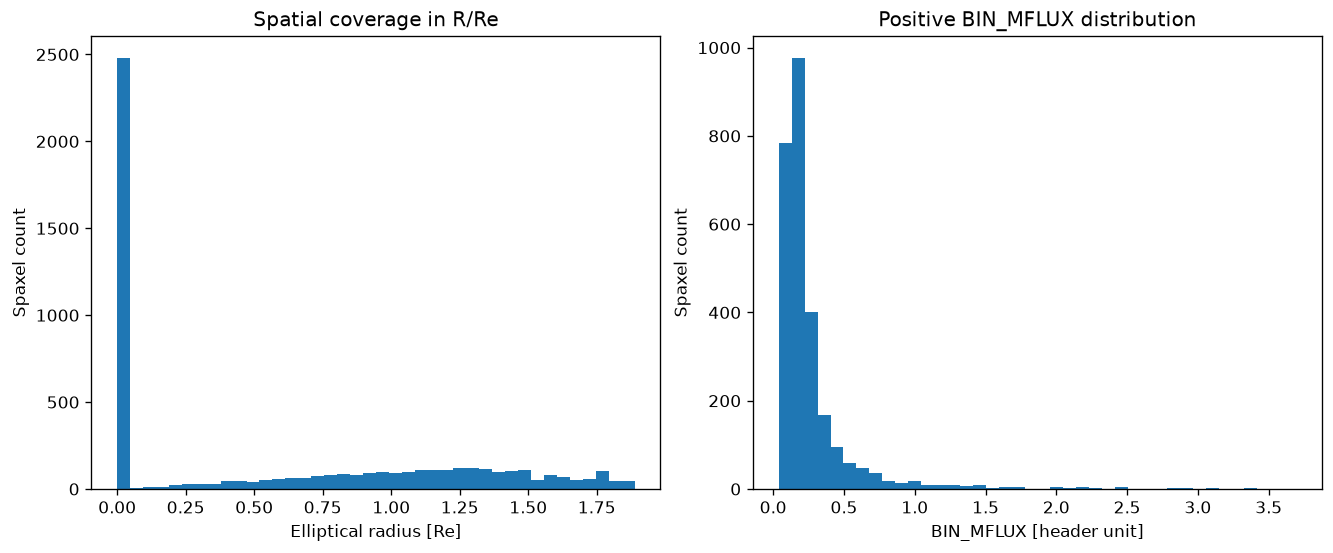

In [13]:
for ext in ["BIN_LWELLCOO", "BIN_LWSKYCOO", "BIN_MFLUX"]:
    hdu = maps[ext]
    print(f"\n{ext}: shape={hdu.data.shape}")
    print("BUNIT:", hdu.header.get("BUNIT"))
    for key in hdu.header:
        if key.startswith(("C", "B")) and key not in ["CHECKSUM"]:
            if key.startswith("C"):
                print(key, "=", hdu.header[key], "/", hdu.header.comments[key])

bin_radius_re = np.asarray(maps["BIN_LWELLCOO"].data[1], dtype=float)
bin_flux_map = np.asarray(maps["BIN_MFLUX"].data, dtype=float)
print("\nR/Re finite range:", np.nanmin(bin_radius_re), np.nanmax(bin_radius_re))
print("Positive BIN_MFLUX fraction:", np.mean(np.isfinite(bin_flux_map) & (bin_flux_map > 0)))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
axes[0].hist(bin_radius_re[np.isfinite(bin_radius_re)], bins=40)
axes[0].set_xlabel("Elliptical radius [Re]")
axes[0].set_ylabel("Spaxel count")
axes[0].set_title("Spatial coverage in R/Re")

axes[1].hist(bin_flux_map[np.isfinite(bin_flux_map) & (bin_flux_map > 0)], bins=40)
axes[1].set_xlabel("BIN_MFLUX [header unit]")
axes[1].set_ylabel("Spaxel count")
axes[1].set_title("Positive BIN_MFLUX distribution")
plt.show()

## 14. Compare the previous reported unique-bin count with the audit

The earlier summary reported 2,194 unique stellar bins. Compare that number with:
- the unique IDs in each BINID plane;
- the number of covered spaxels;
- the number of singleton bins;
- the number of bins with multiple spaxels.

If the number of unique bins equals the number of covered spaxels and almost every bin is a singleton, that is not automatically wrong, but it deserves investigation for a HYB10 stellar-continuum analysis that uses Voronoi binning to a target S/N. Check the selected plane and channel metadata first.

In [14]:
previous_reported_unique_bins = 2194
print("Previous report unique bins:", previous_reported_unique_bins)
display(binid_stats_df)
print("Selected plane unique IDs:", len(stellar_ids))
print("Selected plane covered spaxels:", int(stellar_covered.sum()))
print("Singleton bin fraction:", float(np.mean(stellar_counts == 1)))
print("Median bin size:", float(np.median(stellar_counts)))

Previous report unique bins: 2194


,plane,covered_spaxels,unique_nonnegative_ids,max_spaxels_in_one_bin,largest_bin_fraction
0,0,2704,2194,29,0.010725
1,1,2704,2194,29,0.010725
2,2,2704,2704,1,0.000370
3,3,2704,2704,1,0.000370
4,4,2704,2704,1,0.000370


Selected plane unique IDs: 2194
Selected plane covered spaxels: 2704
Singleton bin fraction: 0.9443938012762079
Median bin size: 1.0


## 15. Save a validation audit report

In [15]:
report_lines = [
    "MaNGA Advanced Kinematic Validation Audit",
    "Target: 8138-12704",
    "DAPTYPE: HYB10-MILESHC-MASTARSSP",
    f"MAPS file: {MAPS_PATH.name}",
    f"Selected stellar BINID plane: {STELLAR_BINID_PLANE}",
    f"Previous reported unique bins: {previous_reported_unique_bins}",
    f"Selected plane covered spaxels: {int(stellar_covered.sum())}",
    f"Selected plane unique IDs: {len(stellar_ids)}",
    f"Singleton bins: {int(np.sum(stellar_counts == 1))}",
    f"Median spaxels per bin: {float(np.median(stellar_counts))}",
    f"95th percentile within-bin velocity range: {vel_range_p95 if 'vel_range_p95' in globals() else float('nan')}",
    f"Velocity standard valid spaxels: {int(vel_standard.sum())}",
    f"Velocity strict valid spaxels: {int(vel_strict.sum())}",
    f"Sigma standard valid spaxels: {int(sigma_standard.sum())}",
    f"Sigma strict valid spaxels: {int(sigma_strict.sum())}",
    f"Velocity mask standard/strict identical: {np.array_equal(vel_standard, vel_strict)}",
    f"Sigma mask standard/strict identical: {np.array_equal(sigma_standard, sigma_strict)}",
    f"BIN representation confirmed by user: {BIN_REPRESENTATION_CONFIRMED}",
    "",
    "BINID plane statistics:",
]
for row in binid_plane_stats:
    report_lines.append(str(row))
report_lines += [
    "",
    "Interpretation note: this audit checks metadata, bin assignments, masks and sampling.",
    "It does not by itself validate a dynamical model or establish an SMBH binary."
]

audit_path = REPORTS_DIR / "advanced_kinematic_validation_audit.txt"
audit_path.write_text("\n".join(report_lines), encoding="utf-8")
print("Saved:", audit_path)
print(audit_path.read_text(encoding="utf-8"))

Saved: D:\KS\manga-stellar-kinematics\outputs\reports\advanced_kinematic_validation_audit.txt
MaNGA Advanced Kinematic Validation Audit
Target: 8138-12704
DAPTYPE: HYB10-MILESHC-MASTARSSP
MAPS file: manga-8138-12704-MAPS-HYB10-MILESHC-MASTARSSP.fits.gz
Selected stellar BINID plane: 0
Previous reported unique bins: 2194
Selected plane covered spaxels: 2704
Selected plane unique IDs: 2194
Singleton bins: 2072
Median spaxels per bin: 1.0
95th percentile within-bin velocity range: 0.0
Velocity standard valid spaxels: 2704
Velocity strict valid spaxels: 2704
Sigma standard valid spaxels: 2704
Sigma strict valid spaxels: 2704
Velocity mask standard/strict identical: True
Sigma mask standard/strict identical: True
BIN representation confirmed by user: False

BINID plane statistics:
{'plane': 0, 'covered_spaxels': 2704, 'unique_nonnegative_ids': 2194, 'max_spaxels_in_one_bin': 29, 'largest_bin_fraction': 0.010724852071005916}
{'plane': 1, 'covered_spaxels': 2704, 'unique_nonnegative_ids': 2194

## 16. Close FITS file

In [16]:
maps.close()
print("MAPS FITS file closed.")

MAPS FITS file closed.


## 17. What to send back

After running this notebook, send:
1. The full `BINID` header printed in Section 3.
2. The `binid_stats_df` table from Section 4.
3. The within-bin spread summaries from Section 7.
4. The mask counts from Section 8 and Section 9.
5. The generated `advanced_kinematic_validation_audit.txt`.

**Do not set `BIN_REPRESENTATION_CONFIRMED = True` until we review these outputs.** If the selected bin plane or within-bin constancy test fails, we will correct the extraction method before recalculating the science metrics.